<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_spinharmoscil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install qiskit[visualization]
!pip install qiskit-aer
!pip install qiskit-ibm-runtime
!pip install pylatexenc
!pip install qiskit-bosons

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from qiskit import transpile, QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import drive
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Operator,Pauli
from scipy.linalg import expm, svd
from qiskit_bosons.operators import BosonOperator, ann, cre
from qiskit_bosons.mappers import LevelSpec
from qiskit_bosons.mappers.library import occupation_encoding
from qiskit.quantum_info import SparsePauliOp
from scipy.linalg import expm, svd
from scipy.interpolate import interp1d


drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
def n_op():
  n = BosonOperator.from_dict({
    (cre(0), ann(0)): 1.0
})
  spec = LevelSpec(3, "gray")
#spec = LevelSpec(3, "standard_binary")


  # 3. Map the operators
  n_gray = occupation_encoding(n, spec)

  n_pauli = SparsePauliOp.from_sparse_observable(n_gray).simplify()
  return n_pauli.to_matrix()

def a_dagger():
  cre_op = BosonOperator.from_dict({
    (cre(0),): 1.0
})
  spec = LevelSpec(3, "gray")
#spec = LevelSpec(3, "standard
  cre_gray = occupation_encoding(cre_op, spec)
  cre_pauli = SparsePauliOp.from_sparse_observable(cre_gray).simplify()
  return cre_pauli.to_matrix()

def a():
  ann_op = BosonOperator.from_dict({
    (ann(0),): 1.0
})
  spec = LevelSpec(3, "gray")
#spec = LevelSpec(3, "standard_binary")
  ann_gray = occupation_encoding(ann_op, spec)
  ann_pauli = SparsePauliOp.from_sparse_observable(ann_gray).simplify()
  return ann_pauli.to_matrix()


In [15]:
def sz_nonoise_spinharmbath_trans(simulator_aer, N = 25, g = 0.7, l= 0.2,delta_t = 0.5, T = 0,omega = 0.5, omega_A = 0.5, omegah = 0.5, nshots = 1024, bosonic = False):
  p_zxx = Pauli('ZXX').to_matrix()
  p_xzx = Pauli('XZX').to_matrix()


  U21 =expm(-1j*l/2*delta_t*(1-np.sqrt(3))*p_zxx)
  U22 = expm(1j*l/2*delta_t*(np.sqrt(2))*p_xzx)
  U21_gate = UnitaryGate(U21, label="U21")
  U22_gate = UnitaryGate(U22, label="U22")




  p_x= Pauli('X').to_matrix()
  p_y = Pauli('Y').to_matrix()

  # We change the sign because of how the basis is chosen
  splus = (1/2)*(p_x-1j*p_y)
  sminus = (1/2)*(p_x+1j*p_y)

  sz_12_nonoise = []
  sz_2_nonoise = []




  if T !=0:
    beta = 1/T
    alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
    if bosonic==True:
      n_B = 1/(np.exp(omega_A/T)-1)
      g = g*np.sqrt(2*n_B+ 1)
      V = g*(np.kron(sminus,a_dagger()) +
       np.kron(splus,a()))
      U1 = expm(-1j*V*delta_t)
      U_gate = UnitaryGate(U1, label="U")
    sz_0_nonoise = []
    for niter in range(0,N+1):
      qc = QuantumCircuit(5,3)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      qc.ry(alpha,3)
      qc.cx(3,4)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,1,2)
        qc.rz(-omegah*2*delta_t,2)

        qc.rz(-omega_A*delta_t,3)

        qc.append(U_gate, [1,2,3])

        qc.rxx(l*delta_t*(1+np.sqrt(3)),0,1)
        qc.rxx(l*delta_t*(np.sqrt(2)),0,2)
        qc.append(U21_gate, [0,1,2])
        qc.append(U22_gate, [0,1,2])

        qc.rz(-omega*delta_t,0)

        qc.reset(3)
        qc.reset(4)
        qc.ry(alpha,3)
        qc.cx(3,4)
      qc.measure(0,0)
      qc.measure(1,1)
      qc.measure(2,2)
      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      sz_12 = 0
      sz_2 = 0
      sz_0 = 0

      for bitstring, count in results.items():

          # Primer qubit (qubit 0)
          sz_12 += (1 if bitstring[-2] == bitstring[-3] else -1) * count

          # Qubit 2: magnetización individual
          sz_2 += (1 if bitstring[-3] == '0' else -1) * count

          sz_0 +=(1 if bitstring[-1] == '0' else -1)*count

      # Normalizamos por el número de shots
      sz_12 /= nshots
      sz_2 /= nshots
      sz_0 /= nshots

      # Guardamos los valores
      sz_12_nonoise.append(sz_12)
      sz_2_nonoise.append(sz_2)
      sz_0_nonoise.append(-sz_0)
  else:
    V = g*(np.kron(sminus,a_dagger()) +
       np.kron(splus,a()))

    U1 = expm(-1j*V*delta_t)
    U_gate = UnitaryGate(U1, label="U")
    sz_0_nonoise = []
    for niter in range(0,N+1):
      qc = QuantumCircuit(4,3)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      #qc.ry(alpha,3)
      #qc.cx(3,4)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,1,2)
        qc.rz(-omegah*2*delta_t,2)

        qc.rz(-omega_A*delta_t,3)

        qc.append(U_gate, [1,2,3])

        qc.rxx(l*delta_t*(1+np.sqrt(3)),0,1)
        qc.rxx(l*delta_t*(np.sqrt(2)),0,2)
        qc.append(U21_gate, [0,1,2])
        qc.append(U22_gate, [0,1,2])

        qc.rz(-omega*delta_t,0)

        qc.reset(3)
        #qc.reset(4)
        #qc.ry(alpha,3)
        #qc.cx(3,4)
      qc.measure(0,0)
      qc.measure(1,1)
      qc.measure(2,2)

      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()

      sz_12 = 0
      sz_2 = 0
      sz_0 = 0

      for bitstring, count in results.items():

          # Primer qubit (qubit 0)
          sz_12 += (1 if bitstring[-2] == bitstring[-3] else -1) * count

          # Qubit 2: magnetización individual
          sz_2 += (1 if bitstring[-3] == '0' else -1) * count

          sz_0 +=(1 if bitstring[-1] == '0' else -1)*count

      # Normalizamos por el número de shots
      sz_12 /= nshots
      sz_2 /= nshots
      sz_0 /= nshots

      # Guardamos los valores
      sz_12_nonoise.append(sz_12)
      sz_2_nonoise.append(sz_2)
      sz_0_nonoise.append(-sz_0)
  return sz_0_nonoise, sz_12_nonoise, sz_2_nonoise

0


KeyboardInterrupt: 

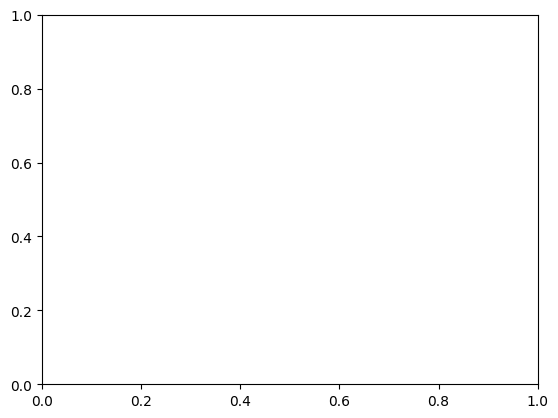

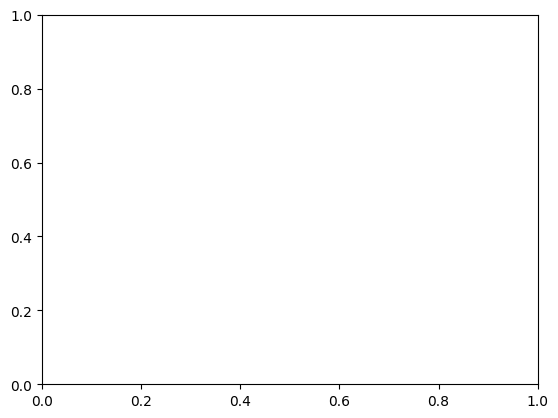

In [25]:
simulator_aer = AerSimulator()
Gamma = 0.25
delta_t = 0.25
g = np.sqrt(Gamma/delta_t)
N = int(25/delta_t)
omega = 0.5
omega_A = 0.5
nshots = 1024
omegah = 0.5
l = 0.25
time = np.arange(N+1) * delta_t

fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()

for T in [0,0.1,0.25,0.5,1]:
  print(T)
  n = []
  sz0,sz12,sz2  = sz_nonoise_spinharmbath_trans(simulator_aer= simulator_aer,  omega = omega,g=g, l=l, N = N, delta_t = delta_t, T = T, omega_A=omega_A, omegah=omegah,bosonic = True, nshots = nshots)

  #sz = sz_nonoise_harmonicosc_long(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, T=T, omega = omega, omega_A=omega_A, omegah=omegah,bosonic = True)
  #sx = sx_nonoise_harmonicosc_long(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, T=T, omega = omega, omega_A=omega_A, omegah=omegah,bosonic = True)
  #sy = sy_nonoise_harmonicosc_long(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t,T=T, omega = omega, omega_A=omega_A, omegah=omegah,bosonic = True)

  for i in range(len(time)):
    n.append(1.5 - sz2[i]-sz12[i]/2 )

  ax_x.plot(time, n, label=rf'$T$={T:.2f}')
  ax_y.plot(time, sz0, label=rf'$T$={T:.2f}')

  datos = np.column_stack((time, n,sz0))

  np.savetxt(
    f"/content/drive/MyDrive/qiskit_spinharmosctrans_bosonicbath_ns{nshots}_nonoise_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_deltat_{delta_t:.2f}_T_{T:.2f}.txt",
    datos,
    header="t n sz0",
    fmt="%.10f"
    )


ax_x.set_xlabel('t', fontsize = 12)
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$', fontsize = 12)
ax_x.set_title(r'Evolution of $\langle a^{\dagger}a\rangle$ ', fontsize = 16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

ax_y.set_xlabel('t', fontsize = 12)
ax_y.set_ylabel(r'$\langle \sigma_x \rangle$', fontsize = 12)
ax_y.set_title(rf'Evolution of $\langle \sigma_z \rangle$ ', fontsize = 16)
ax_y.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


plt.show()

#plt.plot(time, sx_2_nonoise,label=rf'$\langle \sigma_x\rangle$')
#plt.plot(time, sy_2_nonoise,label=rf'$\langle \sigma_y\rangle$')
#plt.plot(time, sz_2_nonoise,label=rf'$\langle \sigma_z\rangle$')

#plt.xlabel('t')
#plt.ylabel('Expected Value')
#plt.legend()


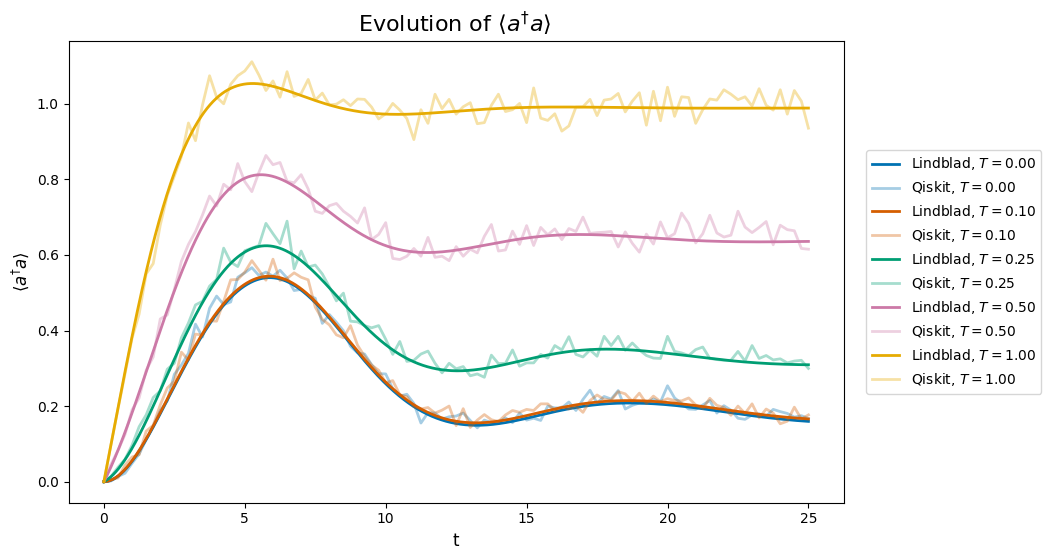

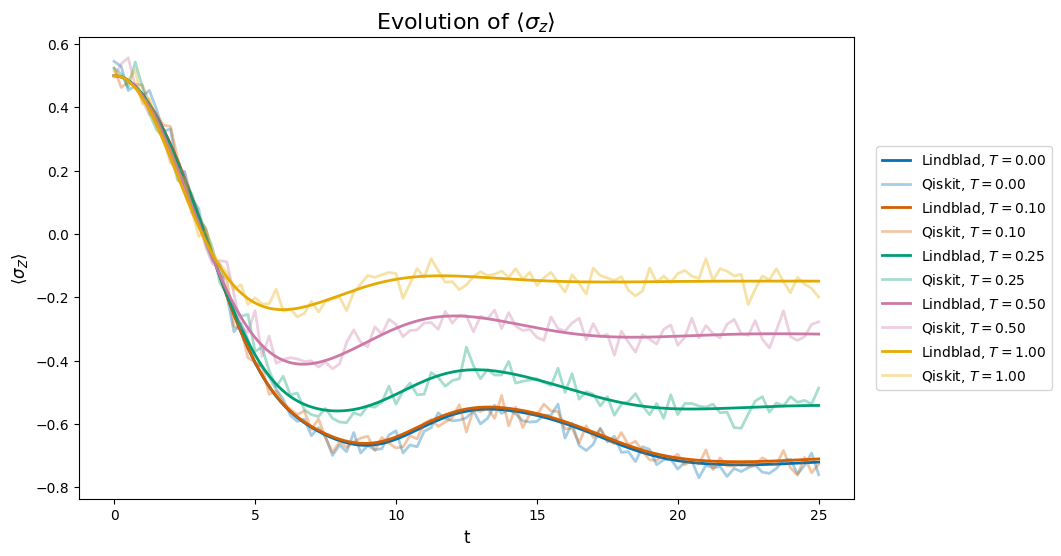

In [28]:

Gamma = 0.25
delta_t = 0.25
g = np.sqrt(Gamma/delta_t)
N = int(25/delta_t)
omega_A = 0.5
nshots = 1024
omegah = 0.5
omega = 0.5
l = 0.25



Ts = [0, 0.1, 0.25, 0.5, 1]

colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E6AB02']



fig_x, ax_x = plt.subplots(figsize=(10, 6))
fig_y, ax_y = plt.subplots(figsize=(10, 6))


for T, color in zip(Ts, colors):

    filename = (
        f"/content/drive/MyDrive/qiskit_spinharmosctrans_bosonicbath_ns{nshots}_nonoise_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_deltat_{delta_t:.2f}_T_{T:.2f}.txt"
    )

    file2 = (
        f"/content/drive/MyDrive/linblad_spinharmosctran_omega_{omega:.2f}_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_l_{l:.2f}_Gamma_{Gamma:.2f}_T_{T:.2f}.txt"
    )

    datos = np.loadtxt(filename, skiprows=1)
    datos2 = np.loadtxt(file2, skiprows=1)

    # Qiskit
    time = datos[:, 0]
    n_qiskit = datos[:, 1]
    sz_qiskit = datos[:, 2]


    # Lindblad
    time2 = datos2[:, 0]
    n_lindblad = datos2[:, 1]
    sz_lindblad = datos2[:, 2]

    # Sigma X
    ax_x.plot(time2, n_lindblad, color=color, linestyle='-',
              linewidth=2, alpha=1,
              label=rf'Lindblad, $T={T:.2f}$')

    ax_x.plot(time, n_qiskit, color=color, linestyle='-',
              linewidth=2, alpha=0.35,
              label=rf'Qiskit, $T={T:.2f}$')

    ax_y.plot(time2, sz_lindblad, color=color, linestyle='-',
              linewidth=2, alpha=1,
              label=rf'Lindblad, $T={T:.2f}$')

    ax_y.plot(time, sz_qiskit, color=color, linestyle='-',
              linewidth=2, alpha=0.35,
              label=rf'Qiskit, $T={T:.2f}$')



# Configuración X
ax_x.set_xlabel('t', fontsize=12)
ax_x.set_ylabel(r'$\langle a^{\dagger}a \rangle$', fontsize=12)
ax_x.set_title(r'Evolution of $\langle a^{\dagger}a \rangle$ ', fontsize=16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

ax_y.set_xlabel('t', fontsize=12)
ax_y.set_ylabel(r'$\langle \sigma_Z \rangle$', fontsize=12)
ax_y.set_title(r'Evolution of $\langle \sigma_z\rangle$ ', fontsize=16)
ax_y.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


plt.show()

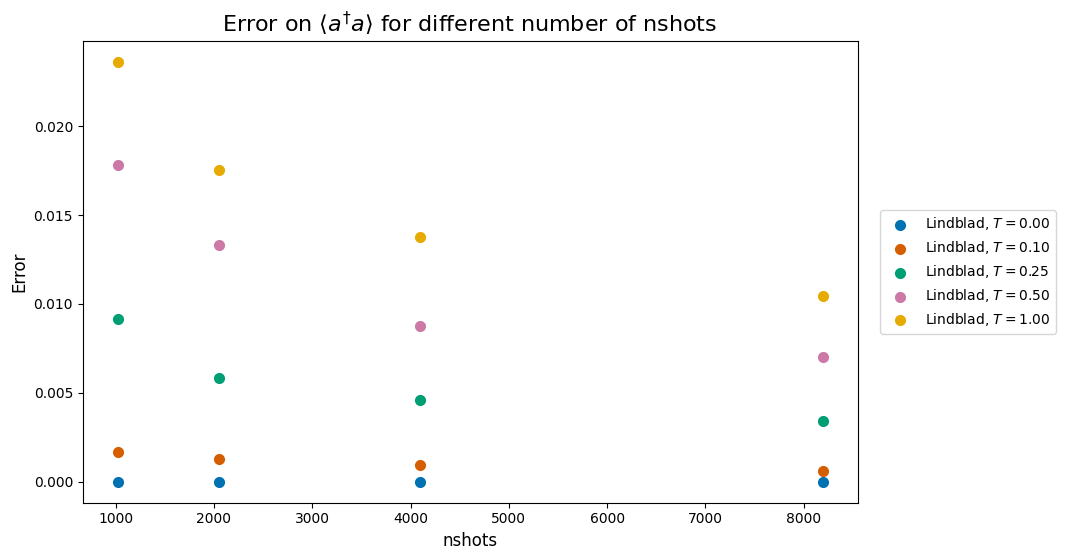

In [ ]:

Gamma = 0.25
delta_t = 0.25
g = np.sqrt(Gamma/delta_t)
omega = 0.5
N = int(25/delta_t)
omega_A = omega
omegah = 0.5



Ts = [0, 0.1, 0.25, 0.5, 1]
nshots_list = [1024, 2048, 4096,8192]

colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E6AB02']



fig_x, ax_x = plt.subplots(figsize=(10, 6))


for T, color in zip(Ts, colors):
  total_error_n = []
  for n_shots in nshots_list:
    nshots = n_shots

    filename = (
        f"/content/drive/MyDrive/qiskit_harmosc_bosonicbath_ns{nshots}_nonoise_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_deltat_{delta_t:.2f}_T_{T:.2f}.txt"
    )

    file2 = (
        f"/content/drive/MyDrive/linblad_harmosc_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_Gamma_{Gamma:.2f}_T_{T:.2f}.txt"
    )

    datos = np.loadtxt(filename, skiprows=1)
    datos2 = np.loadtxt(file2, skiprows=1)

    # Qiskit
    time = datos[:, 0]
    n_qiskit = datos[:, 1]


    # Lindblad
    time2 = datos2[:, 0]
    n_lindblad = datos2[:, 1]

    n_lindblad_interp = interp1d(
    time2, n_lindblad, kind='linear',
    bounds_error=False, fill_value=np.nan
    )

    n_lindblad_near = n_lindblad_interp(time)
    error_n = np.abs(n_qiskit - n_lindblad_near)
    total_error_n.append(np.mean(error_n))


    # Sigma X
  ax_x.scatter(nshots_list, total_error_n, color=color,
            linewidth=2, alpha=1,
            label=rf'Lindblad, $T={T:.2f}$')




# Configuración X
ax_x.set_xlabel('nshots', fontsize=12)
ax_x.set_ylabel(r'Error', fontsize=12)
ax_x.set_title(r'Error on $\langle a^{\dagger}a\rangle$ for different number of nshots ', fontsize=16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))



plt.show()

In [ ]:
g=0.7
p_x= Pauli('X').to_matrix()

p_y = Pauli('Y').to_matrix()
splus = (1/2)*(p_x+1j*p_y)
sminus = (1/2)*(p_x-1j*p_y)

V = g*(np.kron(a_dagger(),sminus) + np.kron(a(),splus))

U1 = expm(-1j*V)
U_gate = UnitaryGate(U1, label="U")

qc = QuantumCircuit(3)
qc.append(U_gate, [0, 1, 2])

# Descomponer
qc_transpiled = transpile(
    qc,
    #basis_gates=["u", "cx"],
    basis_gates=["cz","id", "rx", "rz", "rzz", "sx", "x"],
    optimization_level=0
)

print(qc_transpiled.draw("text"))
print("Número de puertas:")
print(qc_transpiled.count_ops())

print("Profundidad del circuito:")
print(qc_transpiled.depth())

print("Número de puertas de dos qubits:")
print(qc_transpiled.count_ops().get("cx", 0))

global phase: 7π/4
     ┌──────────────┐   ┌────┐  ┌────────────┐   ┌────┐  ┌────────────┐»
q_0: ┤ Rz(-0.50349) ├───┤ √X ├──┤ Rz(4.2541) ├───┤ √X ├──┤ Rz(8.5165) ├»
     ├──────────────┤   ├────┤  ├────────────┤   ├────┤  ├────────────┤»
q_1: ┤ Rz(-0.50154) ├───┤ √X ├──┤ Rz(3.5263) ├───┤ √X ├──┤ Rz(7.6432) ├»
     └─┬──────────┬─┘┌──┴────┴─┐└───┬────┬───┘┌──┴────┴─┐└────────────┘»
q_2: ──┤ Rz(-π/8) ├──┤ Rz(π/2) ├────┤ √X ├────┤ Rz(π/2) ├──────────────»
       └──────────┘  └─────────┘    └────┘    └─────────┘              »
«                                    ┌──────────┐┌────┐┌────────────┐»
«q_0: ─────────────────────────────■─┤ Rz(-π/2) ├┤ √X ├┤ Rz(5.2528) ├»
«     ┌─────────┐┌────┐┌─────────┐ │ ├─────────┬┘├────┤└┬─────────┬─┘»
«q_1: ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├─■─┤ Rz(π/2) ├─┤ √X ├─┤ Rz(π/2) ├──»
«     └─────────┘└────┘└─────────┘   └─────────┘ └────┘ └─────────┘  »
«q_2: ───────────────────────────────────────────────────────────────»
«                                           

In [ ]:
n = BosonOperator.from_dict({
    (cre(0), ann(0)): 1.0
})
spec = LevelSpec(3, "gray")
#spec = LevelSpec(3, "standard_binary")


# 3. Map the operators
n_gray = occupation_encoding(n, spec)

n_pauli = SparsePauliOp.from_sparse_observable(n_gray).simplify()

In [ ]:
n_pauli

SparsePauliOp(['II', 'ZI', 'ZZ'],
              coeffs=[ 1.5+0.j, -1. +0.j, -0.5+0.j])

In [ ]:
print(a())

[[0.        +0.j 1.        +0.j 0.        +0.j 0.        +0.j]
 [0.        +0.j 0.        +0.j 0.        +0.j 1.41421356+0.j]
 [0.        +0.j 0.        +0.j 0.        +0.j 0.        +0.j]
 [0.        +0.j 0.        +0.j 1.73205081+0.j 0.        +0.j]]


In [ ]:
p_x= Pauli('X').to_matrix()
p_y = Pauli('Y').to_matrix()

splus = (1/2)*(p_x+1j*p_y)
sminus = (1/2)*(p_x-1j*p_y)

print(splus)

[[0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j]]


In [ ]:
H =n_op()

U_int = expm(-1j*()*delta_t)
U_gateH = UnitaryGate(U_int, label="U_H")
qc = QuantumCircuit(2)
qc.append(U_gateH, [0, 1])

# Descomponer
qc_transpiled = transpile(
    qc,
    basis_gates=["u", "cx"],
    optimization_level=0
)

print(qc_transpiled.draw("text"))
print("Número de puertas:")
print(qc_transpiled.count_ops())

print("Profundidad del circuito:")
print(qc_transpiled.depth())

print("Número de puertas de dos qubits:")
print(qc_transpiled.count_ops().get("cx", 0))

global phase: 3.802
     ┌───────────────┐            ┌──────────────┐           »
q_0: ┤ U(π,3π/4,π/4) ├───■────────┤ U(π,-π,-π/2) ├────────■──»
     ├───────────────┴┐┌─┴─┐┌─────┴──────────────┴─────┐┌─┴─┐»
q_1: ┤ U(3π/4,-π/2,0) ├┤ X ├┤ U(1.5863,1.7467,-1.7467) ├┤ X ├»
     └────────────────┘└───┘└──────────────────────────┘└───┘»
«        ┌───────────┐    
«q_0: ───┤ U(0,0,-π) ├────
«     ┌──┴───────────┴───┐
«q_1: ┤ U(3π/4,-0.5,π/2) ├
«     └──────────────────┘
Número de puertas:
OrderedDict({'u': 6, 'cx': 2})
Profundidad del circuito:
5
Número de puertas de dos qubits:
2


In [ ]:
print(n_op())

print(np.linalg.eigvalsh(n_op()))

[[2.22044605e-16+0.j 0.00000000e+00+0.j 0.00000000e+00+0.j
  0.00000000e+00+0.j]
 [0.00000000e+00+0.j 1.00000000e+00+0.j 0.00000000e+00+0.j
  0.00000000e+00+0.j]
 [0.00000000e+00+0.j 0.00000000e+00+0.j 3.00000000e+00+0.j
  0.00000000e+00+0.j]
 [0.00000000e+00+0.j 0.00000000e+00+0.j 0.00000000e+00+0.j
  2.00000000e+00+0.j]]
[2.22044605e-16 1.00000000e+00 2.00000000e+00 3.00000000e+00]


In [ ]:
n = n_op()
ad = a_dagger()
a0 = a()

print("Eigenvalues n:")
print(np.linalg.eigvalsh(n))

print("||adag a - n||:")
print(np.linalg.norm(ad @ a0 - n))

print("||a - adag dagger||:")
print(np.linalg.norm(a0 - ad.conj().T))

Eigenvalues n:
[2.22044605e-16 1.00000000e+00 2.00000000e+00 3.00000000e+00]
||adag a - n||:
7.021666937153402e-16
||a - adag dagger||:
0.0


In [ ]:
V = g*(np.kron(a_dagger(),sminus) + np.kron(a(),splus))

In [ ]:
from qiskit.quantum_info import SparsePauliOp

op = SparsePauliOp.from_operator(np.kron(a_dagger(),sminus) + np.kron(a(),splus))

print(op)

SparsePauliOp(['IXX', 'IYY', 'XIX', 'XZX', 'YIY', 'YZY', 'ZXX', 'ZYY'],
              coeffs=[ 0.6830127 +0.j,  0.1830127 -0.j,  0.35355339+0.j, -0.35355339+0.j,
 -0.35355339+0.j,  0.35355339-0.j, -0.1830127 +0.j, -0.6830127 +0.j])


In [ ]:
p_xzx = Pauli('XZX').to_matrix()
p_yzy = Pauli('YZY').to_matrix()
p_zxx = Pauli('ZXX').to_matrix()
p_zyy = Pauli('ZYY').to_matrix()


U1= expm(1j*p_xzx*delta_t)
U2=expm(-1j*p_yzy*delta_t)
U3=expm(1j*p_zxx*delta_t)
U4= expm(1j*p_zyy*delta_t)

U_gate1 = UnitaryGate(U1, label="U1")
U_gate2 = UnitaryGate(U2, label="U2")
U_gate3 = UnitaryGate(U3, label="U3")
U_gate4 = UnitaryGate(U4, label="U4")
qc = QuantumCircuit(3)
qc.rxx(delta_t,0,1)
qc.ryy(delta_t,0,1)
qc.rxx(delta_t,0,2)
qc.append(U_gate1, [0, 1,2])
qc.ryy(-delta_t,0,2)
qc.append(U_gate2, [0, 1,2])
qc.append(U_gate3, [0, 1,2])
qc.append(U_gate4, [0, 1,2])

# Descomponer
qc_transpiled = transpile(
    qc,
    basis_gates=["u", "cx"],
    #basis_gates=["cz","id", "rx", "rz", "rzz", "sx", "x"],
    optimization_level=0
)

print(qc_transpiled.draw("text"))
print("Número de puertas:")
print(qc_transpiled.count_ops())

print("Profundidad del circuito:")
print(qc_transpiled.depth())

print("Número de puertas de dos qubits:")
print(qc_transpiled.count_ops().get("cx", 0))

global phase: 0.61605
     ┌────────────┐                         ┌────────────┐┌─────────────────┐»
q_0: ┤ U(π/2,0,π) ├──■───────────────────■──┤ U(π/2,0,π) ├┤ U(π/2,-π/2,π/2) ├»
     ├────────────┤┌─┴─┐┌─────────────┐┌─┴─┐├────────────┤├─────────────────┤»
q_1: ┤ U(π/2,0,π) ├┤ X ├┤ U(0,0,0.25) ├┤ X ├┤ U(π/2,0,π) ├┤ U(π/2,-π/2,π/2) ├»
     ├────────────┤└───┘└─────────────┘└───┘└────────────┘└─────────────────┘»
q_2: ┤ U(π/2,0,π) ├──────────────────────────────────────────────────────────»
     └────────────┘                                                          »
«                              ┌──────────────────┐┌────────────┐     »
«q_0: ──■───────────────────■──┤ U(-π/2,-π/2,π/2) ├┤ U(π/2,0,π) ├──■──»
«     ┌─┴─┐┌─────────────┐┌─┴─┐├──────────────────┤└────────────┘  │  »
«q_1: ┤ X ├┤ U(0,0,0.25) ├┤ X ├┤ U(-π/2,-π/2,π/2) ├────────────────┼──»
«     └───┘└─────────────┘└───┘└──────────────────┘              ┌─┴─┐»
«q_2: ───────────────────────────────────────────────────────────

In [ ]:
spec = LevelSpec(3, "gray")
#spec = LevelSpec(3, "standard_binary")


# 3. Map the operators
matrix_thermal = np.eye(4)
matrix_thermal[1, 1] = 2
matrix_thermal[2, 2] = 3
matrix_thermal[3, 3] = 4
th = occupation_encoding(, spec)
print(th.to_matrix())

TypeError: argument 'op': 'ndarray' object cannot be cast as 'BosonOperator'

In [ ]:
n = BosonOperator.from_dict({
  (cre(0), ann(0)): 1.0
})
spec = LevelSpec(3, "gray")
#spec = LevelSpec(3, "standard_binary")


# 3. Map the operators
n_gray = occupation_encoding(n, spec)

n_pauli = SparsePauliOp.from_sparse_observable(n_gray).simplify()
n_pauli.to_matrix()

array([[2.22044605e-16+0.j, 0.00000000e+00+0.j, 0.00000000e+00+0.j,
        0.00000000e+00+0.j],
       [0.00000000e+00+0.j, 1.00000000e+00+0.j, 0.00000000e+00+0.j,
        0.00000000e+00+0.j],
       [0.00000000e+00+0.j, 0.00000000e+00+0.j, 3.00000000e+00+0.j,
        0.00000000e+00+0.j],
       [0.00000000e+00+0.j, 0.00000000e+00+0.j, 0.00000000e+00+0.j,
        2.00000000e+00+0.j]])

In [ ]:
print(n_pauli.to_matrix())

[[2.22044605e-16+0.j 0.00000000e+00+0.j 0.00000000e+00+0.j
  0.00000000e+00+0.j]
 [0.00000000e+00+0.j 1.00000000e+00+0.j 0.00000000e+00+0.j
  0.00000000e+00+0.j]
 [0.00000000e+00+0.j 0.00000000e+00+0.j 3.00000000e+00+0.j
  0.00000000e+00+0.j]
 [0.00000000e+00+0.j 0.00000000e+00+0.j 0.00000000e+00+0.j
  2.00000000e+00+0.j]]
